In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [2]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 도형은 크기를 늘리는 편이 좋음!
    transforms.Grayscale(1), # 흑백
    transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 실 이미지 크기를 확인한 후 늘리기!
    transforms.Grayscale(1), # 흑백
    transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [3]:
base_path = r"/Users/hyusoohi5/kdt_0900_khs/ml/resource/"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [4]:
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

print(len(train_dataset), len(test_dataset))

240 60


In [5]:
class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

In [7]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [8]:
imgs, labels = next(iter(train_dataloader))

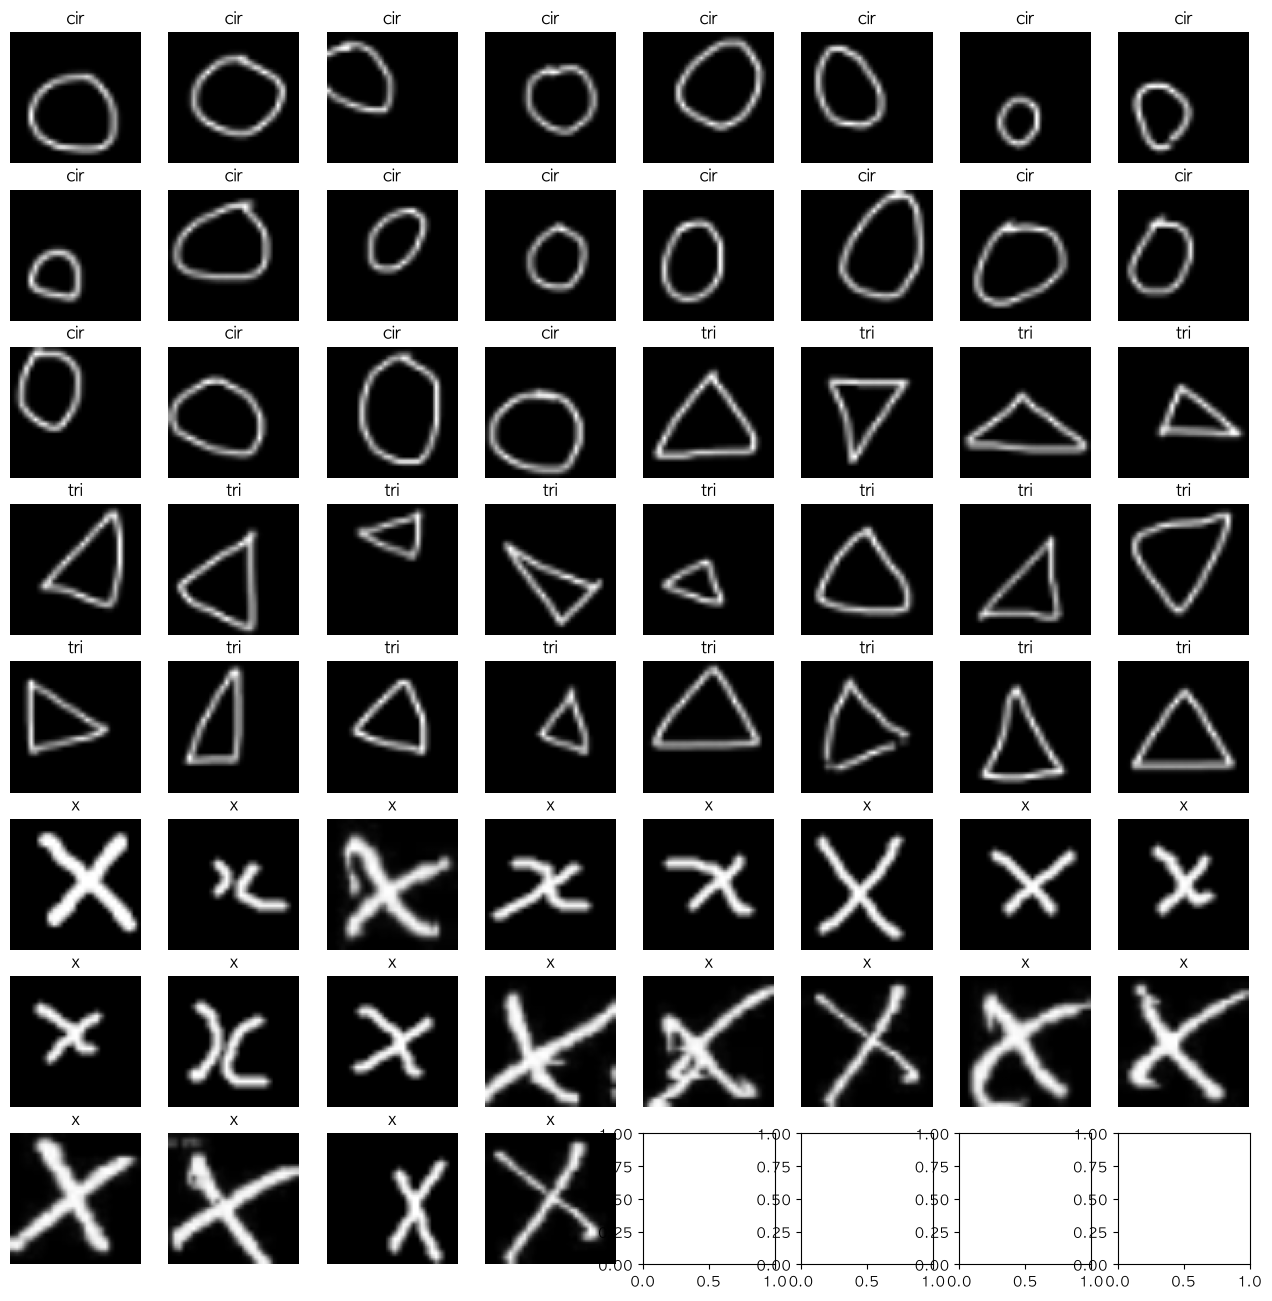

In [20]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))

for ax, img, label in zip (axes.flatten(), imgs, labels):
    ax.imshow(img.reshape(64, 64), cmap="gray")
    ax.set_title(class_dict.get(label.item(), 0))
    ax.axis("off")
    
plt.show()

## CNN을 활용해서 도형 분류하기 실습

In [6]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


## CNN 모델 준비

In [21]:
class ConvNeuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), # 64, 64
            nn.ReLU(), # 활성화 함수(선형 -> 비선형)
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 32, 32
            nn.Dropout(0.25),
            
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 16, 16
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 3)
    
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [10]:
model = ConvNeuralNetwork().to(device)

In [22]:
criterion = nn.CrossEntropyLoss() # 다중 확률로 처리됨. (내부에 소프트맥스를 포함) - Binary Entropy Loss() 함수를 활용해도 좋음!
optimizer = optim.Adam(model.parameters(), lr=0.001) # 가중치의 폭주를 막기 위함

In [28]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [13]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size

    return running_loss / total, running_corrects / total

In [23]:
epochs = 30

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}")

Epoch: 0/30
[Train] Loss: 0.9471 | Accuracy: 87.92
[Test] Loss: 2.6200 | Accuracy: 78.33
Epoch: 1/30
[Train] Loss: 0.7476 | Accuracy: 85.42
[Test] Loss: 1.1447 | Accuracy: 78.33
Epoch: 2/30
[Train] Loss: 0.1540 | Accuracy: 93.33
[Test] Loss: 1.6420 | Accuracy: 70.00
Epoch: 3/30
[Train] Loss: 0.2393 | Accuracy: 86.67
[Test] Loss: 1.1087 | Accuracy: 75.00
Epoch: 4/30
[Train] Loss: 0.1022 | Accuracy: 95.00
[Test] Loss: 1.4495 | Accuracy: 75.00
Epoch: 5/30
[Train] Loss: 0.0794 | Accuracy: 98.33
[Test] Loss: 2.0342 | Accuracy: 76.67
Epoch: 6/30
[Train] Loss: 0.0444 | Accuracy: 98.33
[Test] Loss: 2.4660 | Accuracy: 78.33
Epoch: 7/30
[Train] Loss: 0.0724 | Accuracy: 95.83
[Test] Loss: 1.1622 | Accuracy: 78.33
Epoch: 8/30
[Train] Loss: 0.0580 | Accuracy: 98.33
[Test] Loss: 0.9964 | Accuracy: 81.67
Epoch: 9/30
[Train] Loss: 0.0238 | Accuracy: 100.00
[Test] Loss: 0.9062 | Accuracy: 80.00
Epoch: 10/30
[Train] Loss: 0.0185 | Accuracy: 100.00
[Test] Loss: 0.8668 | Accuracy: 81.67
Epoch: 11/30
[Trai

In [24]:
imgs, labels = next(iter(test_dataloader))

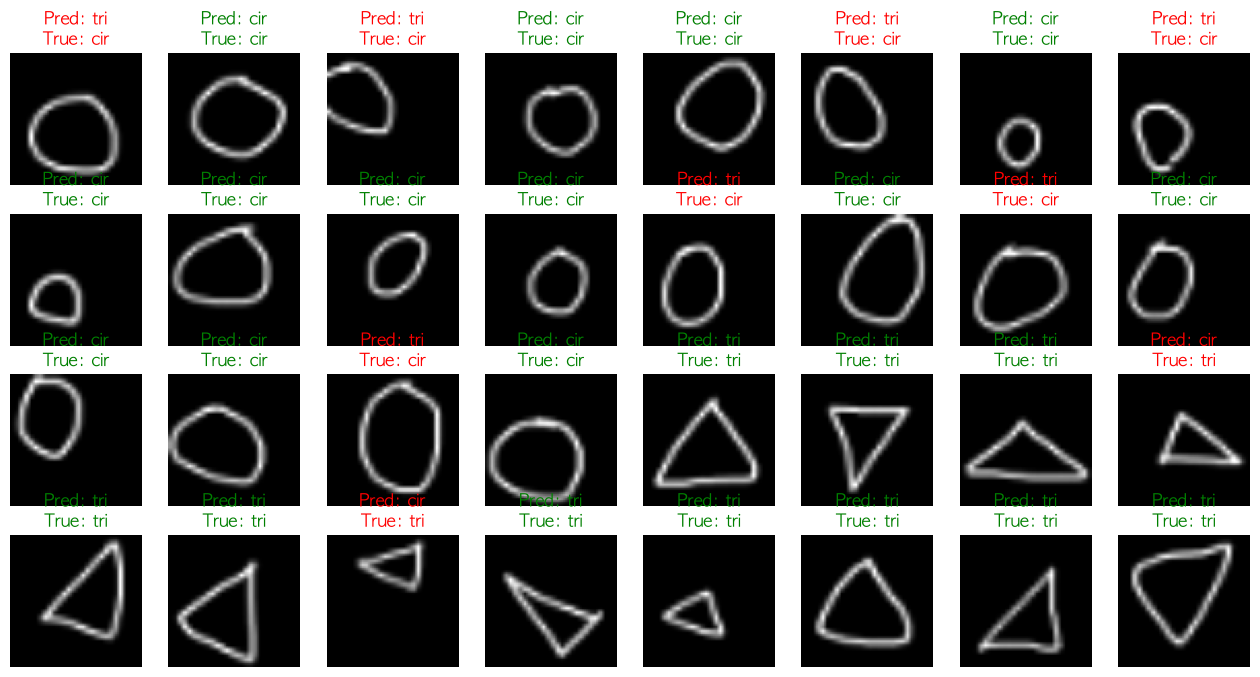

In [15]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")
    # ax.imshow(img.permute(1, 2, 0), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.show()

## 복잡한 도형과 비교 구분하기

In [16]:
shape_path = r"/Users/hyusoohi5/kdt_0900_khs/ml/resource/복잡한 도형.png"
shape_path

'/Users/hyusoohi5/kdt_0900_khs/ml/resource/복잡한 도형.png'

In [17]:
from PIL import Image

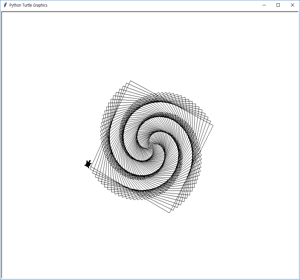

In [26]:
shape = Image.open(shape_path).convert("RGB")
shape = image.resize((300, 280))

shape

예측 결과 : cir | 확률 : 90.50%


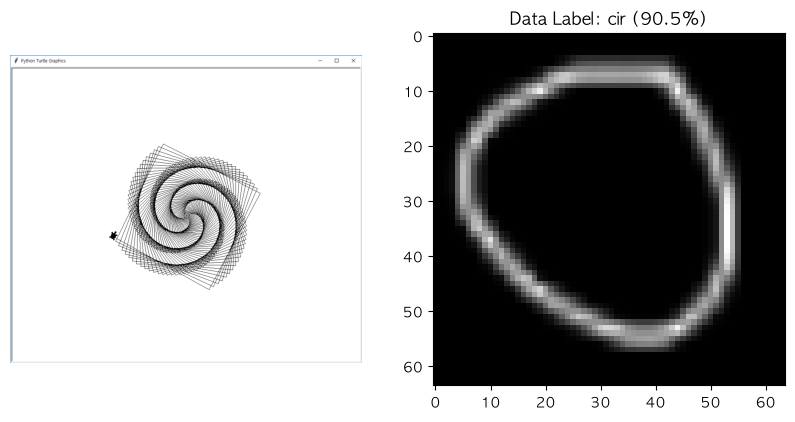

In [33]:
shape = Image.open(shape_path).convert("RGB")
input_tensor = test_transform(shape)

# 1채널 그대로 사용 (차원 추가 필요)
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

    print(f"예측 결과 : {pred_class} | 확률 : {confidence:.2f}%")

dataset_sample_img = None

for sample_img, sample_label in train_dataset:
    if sample_label == pred_idx:
        dataset_sample_img = sample_img
        break

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 0 복잡한 도형
axes[0].imshow(shape)
axes[0].axis("off")

# 예측 클래스와 같은 데이터 예시
if dataset_sample_img is not None:
    axes[1].imshow(
        dataset_sample_img.squeeze(0).numpy(),
        cmap="gray"
    )
    axes[1].set_title(
        f"Data Label: {pred_class} ({confidence:.1f}%)"
    )
else:
    axes[1].set_title("No matching sample found")

## Grad-CAM(Gradient-weighted Class Activation Mapping)
- 딥러닝 인공지능(AI) 모델이 이미지를 보고 어떤 영역을 근거로 특정 클래스(결과)를 예측했는지 시각화해 주는 설명 가능한 AI(XAI, Explainable AI) 기법입니다1m

예측 결과: cir (확률: 90.5%, 클래스 번호: 0)


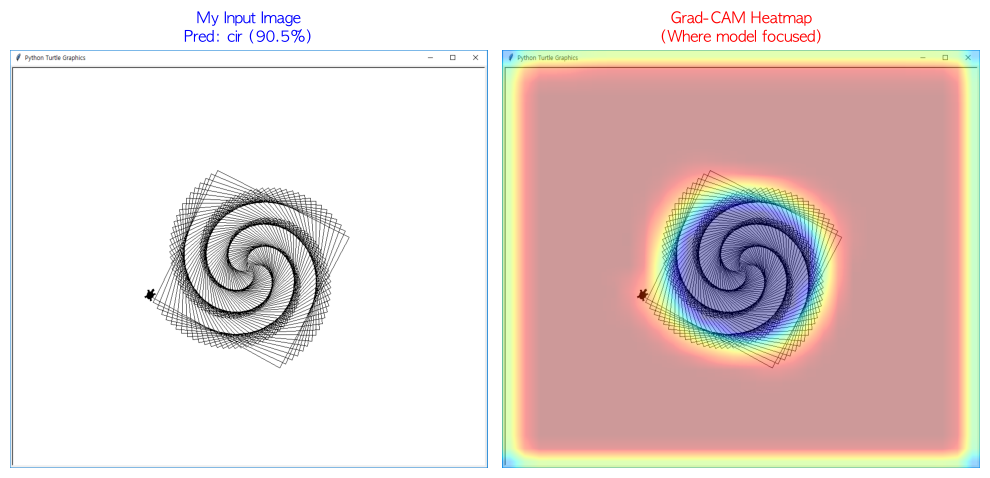

In [34]:
# 훅(Hook)을 사용하여 마지막 Convolution 층의 활성화 값과 그래디언트 추출 준비
activations = None
gradients = None

def forward_hook(module, input, output):
  global activations
  activations = output

def backward_hook(module, grad_input, grad_output):
  global gradients
  gradients = grad_output[0]


# 우리 모델의 classifier(또는 features) 안에서 마지막 Conv 레이어 지정
# 모델 구조에 맞게 마지막 Conv2d 레이어를 타겟으로 잡기
target_layer = model.classifier[-5]  # 마지막 직전 Conv2d 또는 마지막 Conv2d
target_layer.register_forward_hook(forward_hook)
target_layer.register_backward_hook(backward_hook)

# 테스트할 이미지 경로 설정 및 전처리 적용
original_shape = Image.open(shape_path).convert("RGB")

# test_transform 활용
input_tensor = test_transform(original_shape).unsqueeze(0).to(
    device
)  # (C, H, W) -> (1, C, H, W)

# 순전파 및 추론
output = model(input_tensor)
probs = F.softmax(output, dim=1)[0]
pred_idx = torch.argmax(probs).item()
pred_class = class_dict[pred_idx]  # 클래스 이름 딕셔너리 (예: {0: 'circle', ...})
confidence = probs[pred_idx].item() * 100

print(f"예측 결과: {pred_class} (확률: {confidence:.1f}%, 클래스 번호: {pred_idx})")

# Grad-CAM 역전파 및 히트맵 계산
model.zero_grad()
class_score = output[0, pred_idx]
class_score.backward()

# 채널별 중요도 가중치 계산 (GAP 성향 반영)
pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])
for i in range(activations.size(1)):
    activations[:, i, :, :] *= pooled_gradients[i]

heatmap = torch.mean(activations, dim=1).squeeze().cpu().detach().numpy()
heatmap = np.maximum(heatmap, 0)  # ReLU 적용 (양수 기여도만)
if heatmap.max() != 0:
    heatmap /= heatmap.max()  # 0~1 정규화

# PIL을 이용해 히트맵 크기를 원본 이미지 크기에 맞게 조절
heatmap_uint8 = np.uint8(255 * heatmap)
heatmap_pil = Image.fromarray(heatmap_uint8).resize(
    original_shape.size, Image.Resampling.BILINEAR
)

# Matplotlib으로 원본 이미지와 Grad-CAM 오버레이 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 첫 번째: 원본 이미지 및 예측 결과
axes[0].imshow(original_shape)
axes[0].set_title(f"My Input Image\nPred: {pred_class} ({confidence:.1f}%)", fontsize=11, color="blue",)
axes[0].axis("off")

# 두 번째: 원본 위에 히트맵 겹치기 (alpha=0.4로 반투명 효과)
axes[1].imshow(original_shape)
axes[1].imshow(heatmap_pil, cmap="jet", alpha=0.4)  # jet 컬러맵으로 무지개빛 히트맵 표현
axes[1].set_title(f"Grad-CAM Heatmap\n(Where model focused)", fontsize=11, color="red")
axes[1].axis("off")

plt.tight_layout()
plt.show()